In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

df = pd.read_csv("Churn_Modelling.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
display(df.head())

Dataset Shape: (10000, 14)

Column Names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

X = pd.get_dummies(
    X, columns=["Geography", "Gender"], drop_first=True, dtype=int
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (10000, 11)
Target Shape: (10000,)

Target Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Normalization completed.")

Training Data: (8000, 11)
Testing Data: (2000, 11)
Normalization completed.


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("ANN model training completed.")



Epoch 1/30


200/200 [==============================] - 2s 4ms/step - loss: 0.6194 - accuracy: 0.6703 - val_loss: 0.5035 - val_accuracy: 0.8000
Epoch 2/30
200/200 [==============================] - 1s 3ms/step - loss: 0.4809 - accuracy: 0.7978 - val_loss: 0.4421 - val_accuracy: 0.8087
Epoch 3/30
200/200 [==============================] - 1s 3ms/step - loss: 0.4477 - accuracy: 0.8023 - val_loss: 0.4244 - val_accuracy: 0.8250
Epoch 4/30
200/200 [==============================] - 1s 3ms/step - loss: 0.4318 - accuracy: 0.8081 - val_loss: 0.4151 - val_accuracy: 0.8269
Epoch 5/30
200/200 [==============================] - 1s 3ms/step - loss: 0.4251 - accuracy: 0.8152 - val_loss: 0.4075 - val_accuracy: 0.8331
Epoch 6/30
200/200 [==============================] - 1s 3ms/step - loss: 0.4173 - accuracy: 0.8198 - val_loss: 0.3996 - val_accuracy: 0.8381
Epoch 7/30
200/200 [==============================] - 1s 3ms/step - loss: 0.4147 - accuracy: 0.8223 - val_loss: 0.3914 - val_accuracy: 0.8400
Ep

63/63 [==============================] - 0s 3ms/step
Test Accuracy: 85.6 %

Confusion Matrix:
[[1560   33]
 [ 255  152]]


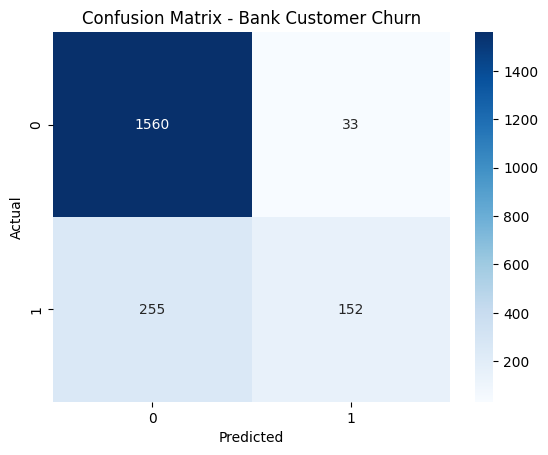

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("\nConfusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Bank Customer Churn")
plt.show()

In [7]:
improved_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("Improved model training completed.")

Epoch 1/50
200/200 [==============================] - 2s 4ms/step - loss: 0.6508 - accuracy: 0.6281 - val_loss: 0.4781 - val_accuracy: 0.8000
Epoch 2/50
200/200 [==============================] - 1s 3ms/step - loss: 0.4826 - accuracy: 0.7956 - val_loss: 0.4422 - val_accuracy: 0.7987
Epoch 3/50
200/200 [==============================] - 1s 3ms/step - loss: 0.4561 - accuracy: 0.7986 - val_loss: 0.4307 - val_accuracy: 0.8062
Epoch 4/50
200/200 [==============================] - 1s 3ms/step - loss: 0.4444 - accuracy: 0.8028 - val_loss: 0.4233 - val_accuracy: 0.8163
Epoch 5/50
200/200 [==============================] - 1s 3ms/step - loss: 0.4360 - accuracy: 0.8125 - val_loss: 0.4139 - val_accuracy: 0.8281
Epoch 6/50
200/200 [==============================] - 1s 3ms/step - loss: 0.4308 - accuracy: 0.8169 - val_loss: 0.4025 - val_accuracy: 0.8388
Epoch 7/50
200/200 [==============================] - 1s 3ms/step - loss: 0.4194 - accuracy: 0.8227 - val_loss: 0.3908 - val_accuracy: 0.8431
Epoch 

63/63 [==============================] - 0s 3ms/step
Improved Model Test Accuracy: 85.95 %

Confusion Matrix:
[[1551   42]
 [ 239  168]]


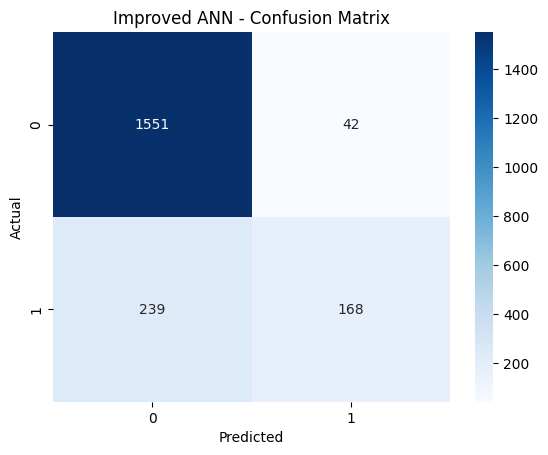

In [8]:
y_pred_prob = improved_model.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Improved Model Test Accuracy:", round(accuracy * 100, 2), "%")
print("\nConfusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Improved ANN - Confusion Matrix")
plt.show()

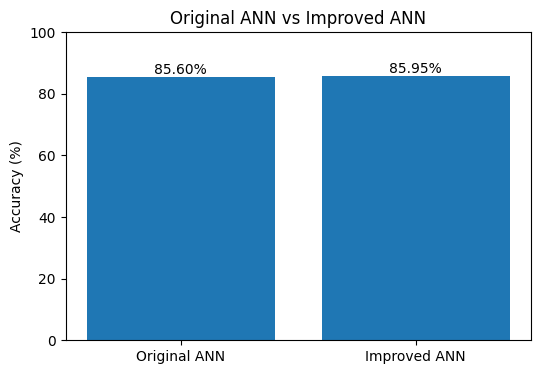

In [9]:
models = ["Original ANN", "Improved ANN"]
accuracies = [85.60, 85.95]

plt.figure(figsize=(6, 4))
plt.bar(models, accuracies)
plt.ylabel("Accuracy (%)")
plt.title("Original ANN vs Improved ANN")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()